# Identificador de Fake News – Preparação, Treinamento e Avaliação

Notebook da segunda etapa do projeto. Implementa a metodologia descrita no artigo:
escolha da versão do corpus, tratamento da duplicação, divisão por pares,
TF-IDF ajustado só no treino, validação cruzada por grupos, comparação de
classificadores, controle do efeito do comprimento e salvamento do modelo final.

In [ ]:
# =============================================================================
# Projeto: Identificador de Fake News
# Disciplina: Inteligência Artificial – 7º CC – Universidade Presbiteriana Mackenzie
# Integrantes:
#     Caio Cesar Navarro Pugliese (RA 10436413) – caiocesar.np@hotmail.com
#     Enzo Maranho Tucilho (RA 10436106) – enzomt2006@gmail.com
# =============================================================================

In [2]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix,
                             f1_score, make_scorer, precision_score,
                             recall_score)
from sklearn.model_selection import (GridSearchCV, GroupKFold,
                                     GroupShuffleSplit, cross_validate)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

import preprocessamento as pp

## 1. Configuração
`CORPUS_DIR` segue a convenção da análise exploratória (`BASE = "full_texts"`): o notebook
roda na pasta que contém `full_texts/` e `size_normalized_texts/`. Se estiver em outro lugar, ajuste o caminho.
`RAPIDO = True` reduz a grade de hiperparâmetros para testar o notebook
antes da execução completa.

In [3]:
CORPUS_DIR = Path(".")
VERSAO_PRINCIPAL = "size_normalized_texts"
VERSAO_COMPARACAO = "full_texts"
VERSOES = [VERSAO_PRINCIPAL, VERSAO_COMPARACAO]

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_FOLDS = 5
N_JOBS = -1
RAPIDO = False

DIR_FIG = Path("graficos")   # mesma pasta da análise exploratória
# No repositório do GitHub: DIR_FIG = Path("Documentacao") / "graficos"
DIR_FIG.mkdir(parents=True, exist_ok=True)
DIR_RES = Path("resultados"); DIR_RES.mkdir(exist_ok=True)
DIR_MOD = Path("modelos"); DIR_MOD.mkdir(exist_ok=True)

COR_FAKE = "#eb6834"   # laranja
COR_TRUE = "#2a78d6"   # azul
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

## 2. Carregamento das duas versões do corpus

In [4]:
dados = {v: pp.carregar_versao(CORPUS_DIR, v) for v in VERSOES}
for v, df in dados.items():
    print(f"{v}: {len(df)} notícias | {df['par_id'].nunique()} pares | "
          f"{df['classe'].value_counts().to_dict()}")

# Conferência: cada par tem exatamente uma notícia fake e uma true
for v, df in dados.items():
    contagem = df.groupby("par_id")["rotulo"].agg(["count", "sum"])
    incompletos = contagem[(contagem["count"] != 2) | (contagem["sum"] != 1)]
    print(f"{v}: pares incompletos = {len(incompletos)}")

size_normalized_texts: 7200 notícias | 3600 pares | {'true': 3600, 'fake': 3600}
full_texts: 7200 notícias | 3600 pares | {'true': 3600, 'fake': 3600}
size_normalized_texts: pares incompletos = 0
full_texts: pares incompletos = 0


## 3. Tratamento da duplicação
Um texto repetido é identificado após normalizar espaços e caixa.
A primeira ocorrência é mantida; o **par inteiro** da ocorrência repetida é
removido das duas versões, para manter o balanceamento e o pareamento.

In [5]:
def pares_duplicados(df):
    norm = df["texto"].str.lower().str.split().str.join(" ")
    dup = norm.duplicated(keep=False)
    grupos = df[dup].assign(texto_norm=norm[dup]).sort_values("par_id")
    if len(grupos):
        print(grupos[["par_id", "classe", "n_palavras"]].assign(
            inicio=grupos["texto"].str[:60]).to_string(index=False))
    repetidos = norm.duplicated(keep="first")
    return set(df.loc[repetidos, "par_id"])

pares_remover = set()
for v, df in dados.items():
    print(f"\n--- Duplicados em {v} ---")
    p = pares_duplicados(df)
    print(f"Pares a remover: {sorted(p)}")
    pares_remover |= p

for v in VERSOES:
    dados[v] = dados[v][~dados[v]["par_id"].isin(pares_remover)].reset_index(drop=True)
    print(f"{v}: {len(dados[v])} notícias após remoção "
          f"({dados[v]['par_id'].nunique()} pares)")

# A numeração do corpus vai de 1 a 3602 e cada versão tem lacunas diferentes.
# Mantêm-se só os pares presentes nas duas versões, para que a comparação
# entre elas use exatamente as mesmas notícias.
ids_p = set(dados[VERSAO_PRINCIPAL]["par_id"])
ids_c = set(dados[VERSAO_COMPARACAO]["par_id"])
print(f"\nPares só em {VERSAO_PRINCIPAL}: {sorted(ids_p - ids_c)}")
print(f"Pares só em {VERSAO_COMPARACAO}: {sorted(ids_c - ids_p)}")
comuns = ids_p & ids_c
for v in VERSOES:
    dados[v] = dados[v][dados[v]["par_id"].isin(comuns)].reset_index(drop=True)
    print(f"{v}: {len(dados[v])} notícias em pares comuns ({dados[v]['par_id'].nunique()} pares)")

# Conferência: o mesmo número corresponde à mesma notícia nas duas versões?
# (compara as 10 primeiras palavras; a versão normalizada é um corte da completa)
m = dados[VERSAO_PRINCIPAL].merge(dados[VERSAO_COMPARACAO], on=["par_id", "classe"],
                                  suffixes=("_n", "_c"))
inicio = lambda s: s.str.split().str[:10].str.join(" ")
alinhados = (inicio(m["texto_n"]) == inicio(m["texto_c"]))
print(f"Mesma notícia nas duas versões: {alinhados.mean():.1%} "
      f"({(~alinhados).sum()} divergentes)")
if (~alinhados).any():
    print(m.loc[~alinhados, ["par_id", "classe"]].head(10).to_string(index=False))


--- Duplicados em size_normalized_texts ---
 par_id classe  n_palavras                                                       inicio
     61   true         130 Suplicy participará de programa de Doria na web nesta quinta
     69   true         130 Suplicy participará de programa de Doria na web nesta quinta
Pares a remover: [69]

--- Duplicados em full_texts ---
 par_id classe  n_palavras                                                       inicio
     61   true         130 Suplicy participará de programa de Doria na web nesta quinta
     69   true         130 Suplicy participará de programa de Doria na web nesta quinta
Pares a remover: [69]
size_normalized_texts: 7198 notícias após remoção (3599 pares)
full_texts: 7198 notícias após remoção (3599 pares)

Pares só em size_normalized_texts: [697, 1468]
Pares só em full_texts: [586, 1607]
size_normalized_texts: 7194 notícias em pares comuns (3597 pares)
full_texts: 7194 notícias em pares comuns (3597 pares)
Mesma notícia nas duas versõe

In [6]:
div = m.loc[~alinhados]
print("Por classe:", div["classe"].value_counts().to_dict())
print("Faixa dos par_id divergentes:", div["par_id"].min(), "a", div["par_id"].max())
print("Primeiros ids:", sorted(div["par_id"].unique())[:30])
for _, r in div.head(4).iterrows():
    print(f"\n--- par {r['par_id']} ({r['classe']}) ---")
    print("normalizada:", repr(r["texto_n"][:120]))
    print("completa:   ", repr(r["texto_c"][:120]))

Por classe: {'true': 76, 'fake': 12}
Faixa dos par_id divergentes: 39 a 3553
Primeiros ids: [np.int64(39), np.int64(63), np.int64(142), np.int64(295), np.int64(303), np.int64(335), np.int64(382), np.int64(385), np.int64(393), np.int64(406), np.int64(419), np.int64(463), np.int64(541), np.int64(545), np.int64(546), np.int64(561), np.int64(654), np.int64(684), np.int64(776), np.int64(795), np.int64(877), np.int64(889), np.int64(908), np.int64(932), np.int64(985), np.int64(991), np.int64(992), np.int64(1010), np.int64(1077), np.int64(1101)]

--- par 39 (true) ---
normalizada: 'Um ano após 1º caso oficial de zika, microcefalia faz bebê tomar até Rivotril Diante dos desafios do tratamento para uma'
completa:    'Um ano após 1o caso oficial de zika, microcefalia faz bebê tomar até Rivotril\nDiante dos desafios do tratamento para uma'

--- par 63 (true) ---
normalizada: 'Lula lidera e enfrentaria Bolsonaro no 2º turno se eleição fosse hoje DE SÃO PAULO O ex-presidente Lula (PT) lidera os c'
c

## 4. Comprimento dos textos nas duas versões
Verifica se a versão normalizada de fato elimina a diferença de tamanho entre classes.

                                mean  median    std
versao                classe                       
full_texts            fake     185.7   157.0  126.4
                      true    1101.0   919.0  682.9
size_normalized_texts fake     182.9   157.0  115.7
                      true     184.4   158.0  116.0


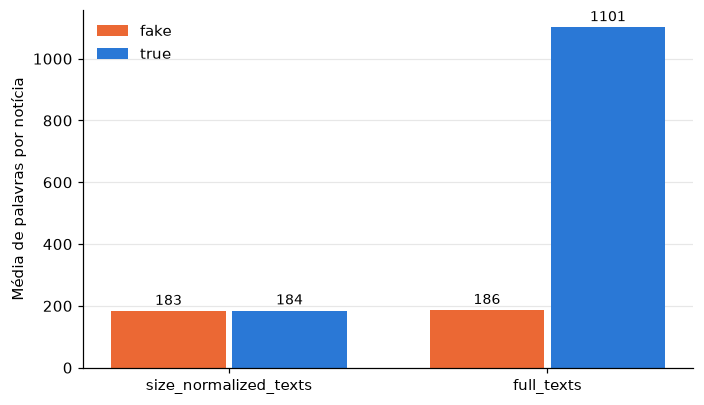

In [7]:
resumo_comp = (pd.concat([d.assign(versao=v) for v, d in dados.items()])
               .groupby(["versao", "classe"])["n_palavras"]
               .agg(["mean", "median", "std"]).round(1))
print(resumo_comp)
resumo_comp.to_csv(DIR_RES / "comprimento_por_versao.csv")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.arange(len(VERSOES)); w = 0.36
for i, (classe, cor) in enumerate([("fake", COR_FAKE), ("true", COR_TRUE)]):
    medias = [resumo_comp.loc[(v, classe), "mean"] for v in VERSOES]
    barras = ax.bar(x + (i - 0.5) * (w + 0.02), medias, w, color=cor, label=classe)
    ax.bar_label(barras, fmt="%.0f", padding=2, fontsize=9)
ax.set_xticks(x, VERSOES)
ax.set_ylabel("Média de palavras por notícia")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(DIR_FIG / "08_comprimento_por_versao.png")
plt.show()

## 5. Pré-processamento
Limpeza por texto (sem estatísticas do conjunto → sem vazamento):
minúsculas, remoção de URLs, números, pontuação, palavras de 1 caractere e
stopwords; e uma segunda coluna com radicalização RSLP.

In [8]:
for v in VERSOES:
    t0 = time.time()
    dados[v]["texto_limpo"] = pp.limpar_lote(dados[v]["texto"])
    dados[v]["texto_radical"] = pp.limpar_lote(dados[v]["texto"], radicalizar=True)
    print(f"{v}: pré-processamento em {time.time() - t0:.0f}s")

print(dados[VERSAO_PRINCIPAL][["texto_limpo", "texto_radical"]].iloc[0].str[:150].to_dict())

size_normalized_texts: pré-processamento em 3s
full_texts: pré-processamento em 6s
{'texto_limpo': 'podemos decidiu expulsar deputado federal carlos gaguim partido após polícia federal fazer buscas apreensões gabinete câmara legenda abre espaço receb', 'texto_radical': 'pod decid expuls deput feder carl gaguim part após políci feder faz busc apreens gabinet câm legend abr espaç receb sen expuls pmdb kat abr mei not le'}


## 6. Divisão treino/teste por pares (80/20)
A divisão é sorteada sobre os identificadores de par e aplicada igualmente
às duas versões, de modo que os experimentos fiquem comparáveis.

In [9]:
base = dados[VERSAO_PRINCIPAL]
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
idx_tr, idx_te = next(gss.split(base, base["rotulo"], groups=base["par_id"]))
pares_treino = set(base.iloc[idx_tr]["par_id"])
pares_teste = set(base.iloc[idx_te]["par_id"])
assert not pares_treino & pares_teste

treino = {v: d[d["par_id"].isin(pares_treino)].reset_index(drop=True) for v, d in dados.items()}
teste = {v: d[d["par_id"].isin(pares_teste)].reset_index(drop=True) for v, d in dados.items()}

divisao = pd.DataFrame({
    "conjunto": ["treino", "teste"],
    "pares": [len(pares_treino), len(pares_teste)],
    "noticias": [len(treino[VERSAO_PRINCIPAL]), len(teste[VERSAO_PRINCIPAL])],
    "fake": [treino[VERSAO_PRINCIPAL]["rotulo"].sum(), teste[VERSAO_PRINCIPAL]["rotulo"].sum()],
})
divisao["true"] = divisao["noticias"] - divisao["fake"]
print(divisao.to_string(index=False))
divisao.to_csv(DIR_RES / "divisao_treino_teste.csv", index=False)
pd.Series(sorted(pares_teste)).to_csv(DIR_RES / "pares_teste.csv", index=False, header=["par_id"])

conjunto  pares  noticias  fake  true
  treino   2877      5754  2877  2877
   teste    720      1440   720   720


## 7. Modelo de referência: só o comprimento
Regressão Logística cuja única entrada é log(1 + número de palavras).
Se ele já acerta muito, o comprimento sozinho separa as classes naquela versão.

In [10]:
cv = GroupKFold(n_splits=N_FOLDS)
SCORING = {"accuracy": "accuracy",
           "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
           "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
           "f1_macro": make_scorer(f1_score, average="macro", zero_division=0)}

def metricas_teste(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, pred),
            "precision_macro": precision_score(y, pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
            "recall_fake": tp / (tp + fn) if (tp + fn) else 0.0,
            "taxa_falso_positivo": fp / (fp + tn) if (fp + tn) else 0.0}

baseline = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("esc", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

linhas_base = []
for v in VERSOES:
    Xtr = treino[v][["n_palavras"]].to_numpy(float)
    Xte = teste[v][["n_palavras"]].to_numpy(float)
    ytr, yte = treino[v]["rotulo"], teste[v]["rotulo"]
    r = cross_validate(baseline, Xtr, ytr, groups=treino[v]["par_id"], cv=cv, scoring=SCORING)
    m = clone(baseline).fit(Xtr, ytr)
    linhas_base.append({"versao": v,
                        "cv_f1_macro": r["test_f1_macro"].mean(),
                        "cv_f1_macro_dp": r["test_f1_macro"].std(),
                        **{f"teste_{k}": val for k, val in metricas_teste(yte, m.predict(Xte)).items()}})

res_base = pd.DataFrame(linhas_base).round(4)
print(res_base.to_string(index=False))
res_base.to_csv(DIR_RES / "baseline_comprimento.csv", index=False)

               versao  cv_f1_macro  cv_f1_macro_dp  teste_accuracy  teste_precision_macro  teste_recall_macro  teste_f1_macro  teste_recall_fake  teste_taxa_falso_positivo
size_normalized_texts       0.5042          0.0029          0.5035                 0.5035              0.5035          0.5035             0.5056                     0.4986
           full_texts       0.9425          0.0083          0.9382                 0.9383              0.9382          0.9382             0.9444                     0.0681


## 8. Ajuste de hiperparâmetros (GridSearchCV + GroupKFold)
O `TfidfVectorizer` está **dentro** do pipeline: em cada fold, vocabulário e
IDF são calculados só com os folds de treino. A radicalização é comparada
rodando a busca sobre as duas colunas de texto. Critério: F1-score macro.

In [11]:
TFIDF_FIXO = dict(sublinear_tf=True, min_df=2, max_df=0.95)

if RAPIDO:
    GRADES = {
        "Naive Bayes": (MultinomialNB(),
                        {"tfidf__ngram_range": [(1, 1)], "tfidf__max_features": [5000],
                         "clf__alpha": [0.1, 1.0]}),
        "Regressão Logística": (LogisticRegression(solver="liblinear", max_iter=1000,
                                                   random_state=RANDOM_STATE),
                                {"tfidf__ngram_range": [(1, 1)], "tfidf__max_features": [5000],
                                 "clf__C": [1, 10]}),
        "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
                          {"tfidf__ngram_range": [(1, 1)], "tfidf__max_features": [5000]}),
    }
else:
    GRADE_TFIDF = {"tfidf__ngram_range": [(1, 1), (1, 2)],
                   "tfidf__max_features": [5000, 10000, 20000]}
    GRADES = {
        "Naive Bayes": (MultinomialNB(),
                        {**GRADE_TFIDF, "clf__alpha": [0.01, 0.1, 0.5, 1.0]}),
        "Regressão Logística": (LogisticRegression(solver="liblinear", max_iter=1000,
                                                   random_state=RANDOM_STATE),
                                {**GRADE_TFIDF, "clf__C": [0.1, 1, 10]}),
        # Random Forest: grade reduzida (só unigramas, 200 árvores) por custo computacional
        "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
                          {"tfidf__ngram_range": [(1, 1)],
                           "tfidf__max_features": [5000, 10000, 20000],
                           "clf__max_depth": [None, 50],
                           "clf__min_samples_leaf": [1, 2]}),
    }

COLUNAS_TEXTO = {"sem radicalização": "texto_limpo", "com radicalização": "texto_radical"}

buscas = {}      # (versao, coluna, modelo) -> GridSearchCV ajustado
linhas_cv = []
for v in VERSOES:   # a versão principal vem primeiro
    for nome_mod, (clf, grade) in GRADES.items():
        if v == VERSAO_PRINCIPAL:
            colunas = list(COLUNAS_TEXTO)   # compara com e sem radicalização
        else:
            # na versão de comparação, usa a opção que venceu na versão principal
            colunas = [max((l for l in linhas_cv if l["versao"] == VERSAO_PRINCIPAL
                            and l["modelo"] == nome_mod),
                           key=lambda l: l["cv_f1_macro"])["texto"]]
        for nome_col in colunas:
            col = COLUNAS_TEXTO[nome_col]
            t0 = time.time()
            pipe = Pipeline([("tfidf", TfidfVectorizer(**TFIDF_FIXO)), ("clf", clone(clf))])
            busca = GridSearchCV(pipe, grade, scoring=SCORING, refit="f1_macro",
                                 cv=cv, n_jobs=N_JOBS)
            busca.fit(treino[v][col], treino[v]["rotulo"], groups=treino[v]["par_id"])
            buscas[(v, nome_col, nome_mod)] = busca
            i = busca.best_index_
            cvr = busca.cv_results_
            linhas_cv.append({
                "versao": v, "texto": nome_col, "modelo": nome_mod,
                **{f"cv_{k}": cvr[f"mean_test_{k}"][i] for k in SCORING},
                "cv_f1_macro_dp": cvr["std_test_f1_macro"][i],
                "melhores_parametros": json.dumps({k: str(val) for k, val in busca.best_params_.items()},
                                                  ensure_ascii=False),
                "tempo_s": round(time.time() - t0, 1),
            })
            print(f"[{v} | {nome_col} | {nome_mod}] F1 cv = {cvr['mean_test_f1_macro'][i]:.4f} "
                  f"± {cvr['std_test_f1_macro'][i]:.4f}  ({time.time() - t0:.0f}s)")

res_cv = pd.DataFrame(linhas_cv)
res_cv.to_csv(DIR_RES / "validacao_cruzada.csv", index=False)
res_cv.drop(columns="melhores_parametros").round(4)

[size_normalized_texts | sem radicalização | Naive Bayes] F1 cv = 0.8872 ± 0.0084  (43s)
[size_normalized_texts | com radicalização | Naive Bayes] F1 cv = 0.8825 ± 0.0126  (32s)
[size_normalized_texts | sem radicalização | Regressão Logística] F1 cv = 0.9223 ± 0.0081  (30s)
[size_normalized_texts | com radicalização | Regressão Logística] F1 cv = 0.9192 ± 0.0062  (27s)
[size_normalized_texts | sem radicalização | Random Forest] F1 cv = 0.8908 ± 0.0077  (74s)
[size_normalized_texts | com radicalização | Random Forest] F1 cv = 0.8844 ± 0.0139  (74s)
[full_texts | sem radicalização | Naive Bayes] F1 cv = 0.9007 ± 0.0055  (135s)
[full_texts | sem radicalização | Regressão Logística] F1 cv = 0.9727 ± 0.0044  (110s)
[full_texts | sem radicalização | Random Forest] F1 cv = 0.9614 ± 0.0048  (104s)


,versao,texto,modelo,cv_accuracy,cv_precision_macro,cv_recall_macro,cv_f1_macro,cv_f1_macro_dp,tempo_s
0,size_normalized_texts,sem radicalização,Naive Bayes,0.8872,0.8877,0.8872,0.8872,0.0084,43.2
1,size_normalized_texts,com radicalização,Naive Bayes,0.8825,0.8830,0.8825,0.8825,0.0126,32.4
2,size_normalized_texts,sem radicalização,Regressão Logística,0.9223,0.9224,0.9223,0.9223,0.0081,30.3
3,size_normalized_texts,com radicalização,Regressão Logística,0.9192,0.9193,0.9192,0.9192,0.0062,27.3
4,size_normalized_texts,sem radicalização,Random Forest,0.8909,0.8910,0.8909,0.8908,0.0077,74.4
5,size_normalized_texts,com radicalização,Random Forest,0.8844,0.8847,0.8844,0.8844,0.0139,74.5
6,full_texts,sem radicalização,Naive Bayes,0.9009,0.9049,0.9009,0.9007,0.0055,134.5
7,full_texts,sem radicalização,Regressão Logística,0.9727,0.9727,0.9727,0.9727,0.0044,109.7
8,full_texts,sem radicalização,Random Forest,0.9614,0.9615,0.9614,0.9614,0.0048,104.3


## 9. Avaliação final no conjunto de teste
Para cada versão e modelo, escolhe-se a coluna de texto (com/sem radicalização)
com maior F1 na validação cruzada. O `best_estimator_` já foi reajustado pelo
GridSearchCV com todo o treino; o teste é usado apenas aqui.

In [12]:
melhores = (res_cv.sort_values("cv_f1_macro", ascending=False)
            .groupby(["versao", "modelo"], as_index=False).first())

linhas_te = []
for _, r in melhores.iterrows():
    v, nome_col, nome_mod = r["versao"], r["texto"], r["modelo"]
    modelo = buscas[(v, nome_col, nome_mod)].best_estimator_
    pred = modelo.predict(teste[v][COLUNAS_TEXTO[nome_col]])
    linhas_te.append({"versao": v, "modelo": nome_mod, "texto": nome_col,
                      "cv_f1_macro": r["cv_f1_macro"],
                      **{f"teste_{k}": val for k, val in metricas_teste(teste[v]["rotulo"], pred).items()}})

res_te = pd.DataFrame(linhas_te).sort_values(["versao", "cv_f1_macro"], ascending=[False, False])
res_te.to_csv(DIR_RES / "resultados_teste.csv", index=False)
res_te.round(4)

,versao,modelo,texto,cv_f1_macro,teste_accuracy,teste_precision_macro,teste_recall_macro,teste_f1_macro,teste_recall_fake,teste_taxa_falso_positivo
5,size_normalized_texts,Regressão Logística,sem radicalização,0.9223,0.9285,0.9285,0.9285,0.9285,0.9347,0.0778
4,size_normalized_texts,Random Forest,sem radicalização,0.8908,0.8847,0.8849,0.8847,0.8847,0.8958,0.1264
3,size_normalized_texts,Naive Bayes,sem radicalização,0.8872,0.8889,0.8892,0.8889,0.8889,0.9028,0.1250
2,full_texts,Regressão Logística,sem radicalização,0.9727,0.9764,0.9765,0.9764,0.9764,0.9833,0.0306
1,full_texts,Random Forest,sem radicalização,0.9614,0.9681,0.9681,0.9681,0.9681,0.9708,0.0347
0,full_texts,Naive Bayes,sem radicalização,0.9007,0.9160,0.9188,0.9160,0.9158,0.8750,0.0431


### Relatório por classe e matrizes de confusão (versão principal)


=== Naive Bayes (sem radicalização) ===
              precision    recall  f1-score   support

        true     0.9000    0.8750    0.8873       720
        fake     0.8784    0.9028    0.8904       720

    accuracy                         0.8889      1440
   macro avg     0.8892    0.8889    0.8889      1440
weighted avg     0.8892    0.8889    0.8889      1440


=== Random Forest (sem radicalização) ===
              precision    recall  f1-score   support

        true     0.8935    0.8736    0.8834       720
        fake     0.8764    0.8958    0.8860       720

    accuracy                         0.8847      1440
   macro avg     0.8849    0.8847    0.8847      1440
weighted avg     0.8849    0.8847    0.8847      1440


=== Regressão Logística (sem radicalização) ===
              precision    recall  f1-score   support

        true     0.9339    0.9222    0.9280       720
        fake     0.9232    0.9347    0.9289       720

    accuracy                         0.9285      

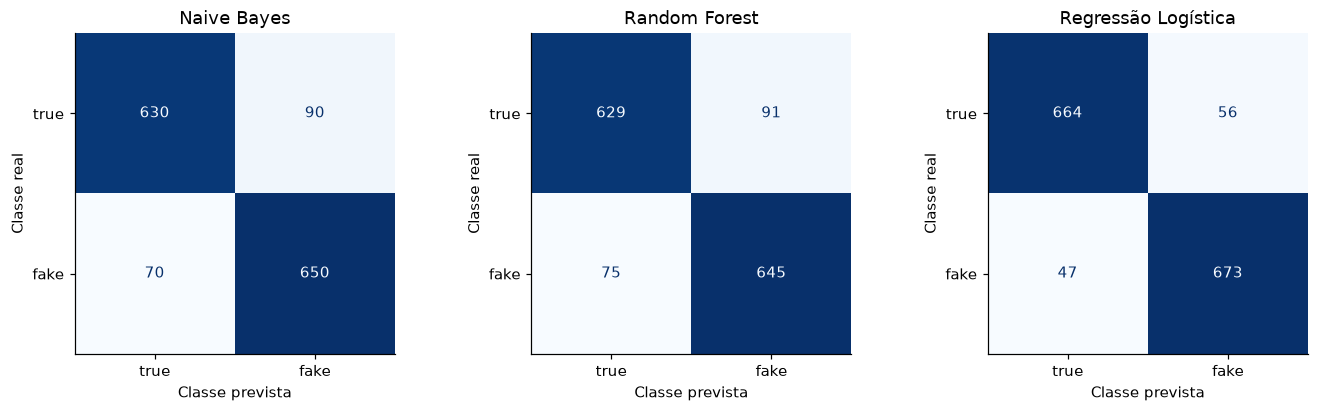

In [13]:
sub = melhores[melhores["versao"] == VERSAO_PRINCIPAL].sort_values("modelo")
fig, axes = plt.subplots(1, len(sub), figsize=(4.2 * len(sub), 3.8))
for ax, (_, r) in zip(np.atleast_1d(axes), sub.iterrows()):
    modelo = buscas[(VERSAO_PRINCIPAL, r["texto"], r["modelo"])].best_estimator_
    y = teste[VERSAO_PRINCIPAL]["rotulo"]
    pred = modelo.predict(teste[VERSAO_PRINCIPAL][COLUNAS_TEXTO[r["texto"]]])
    print(f"\n=== {r['modelo']} ({r['texto']}) ===")
    print(classification_report(y, pred, target_names=["true", "fake"], digits=4, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=[0, 1]),
                           display_labels=["true", "fake"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(r["modelo"])
    ax.set_xlabel("Classe prevista"); ax.set_ylabel("Classe real")
plt.tight_layout()
plt.savefig(DIR_FIG / "09_matrizes_confusao.png")
plt.show()

### Comparação das versões: o quanto o comprimento infla o resultado

versao                       size_normalized_texts  full_texts
modelo                                                        
Naive Bayes                                 0.8889      0.9158
Random Forest                               0.8847      0.9681
Regressão Logística                         0.9285      0.9764
Só comprimento (referência)                 0.5035      0.9382


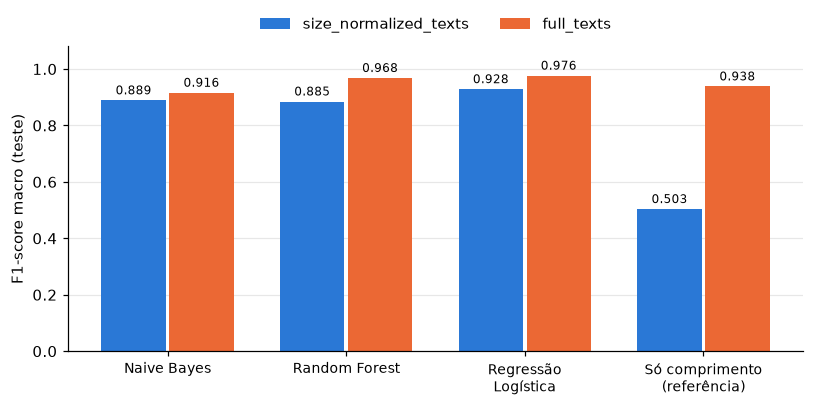

In [18]:
comp = res_te.pivot(index="modelo", columns="versao", values="teste_f1_macro")
comp.loc["Só comprimento (referência)"] = res_base.set_index("versao")["teste_f1_macro"]
comp = comp[VERSOES]
print(comp.round(4))
comp.to_csv(DIR_RES / "comparacao_versoes.csv")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(comp)); w = 0.36
cores_versao = {VERSAO_PRINCIPAL: "#2a78d6", VERSAO_COMPARACAO: "#eb6834"}
for i, v in enumerate(VERSOES):
    barras = ax.bar(x + (i - 0.5) * (w + 0.02), comp[v], w, color=cores_versao[v], label=v)
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=8)
rotulos = {"Regressão Logística": "Regressão\nLogística",
           "Só comprimento (referência)": "Só comprimento\n(referência)"}
ax.set_xticks(x, [rotulos.get(m, m) for m in comp.index], fontsize=9)
ax.set_ylabel("F1-score macro (teste)")
ax.set_ylim(0, 1.08)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(DIR_FIG / "10_comparacao_versoes.png")
plt.show()

## 10. Modelo final para o protótipo
Escolha pelo maior F1 macro na **validação cruzada** da versão principal
(não pelo teste). O pipeline salvo inclui o pré-processamento, então recebe
o texto bruto da notícia.

In [15]:
escolhido = (res_cv[res_cv["versao"] == VERSAO_PRINCIPAL]
             .sort_values("cv_f1_macro", ascending=False).iloc[0])
print("Modelo escolhido:", escolhido["modelo"], "|", escolhido["texto"],
      "| F1 cv =", round(escolhido["cv_f1_macro"], 4))

melhor = buscas[(VERSAO_PRINCIPAL, escolhido["texto"], escolhido["modelo"])].best_estimator_
func_prep = pp.limpar_lote_radicalizado if escolhido["texto"] == "com radicalização" else pp.limpar_lote

modelo_final = Pipeline([("prep", FunctionTransformer(func_prep))]
                        + [(nome, clone(passo)) for nome, passo in melhor.steps])
modelo_final.fit(treino[VERSAO_PRINCIPAL]["texto"], treino[VERSAO_PRINCIPAL]["rotulo"])

# Conferência: o pipeline com texto bruto reproduz o resultado do teste
pred_final = modelo_final.predict(teste[VERSAO_PRINCIPAL]["texto"])
print("F1 macro no teste (pipeline final):",
      round(f1_score(teste[VERSAO_PRINCIPAL]["rotulo"], pred_final, average="macro"), 4))

joblib.dump(modelo_final, DIR_MOD / "modelo_final.joblib")
metadados = {
    "modelo": escolhido["modelo"], "texto": escolhido["texto"],
    "versao_corpus": VERSAO_PRINCIPAL,
    "parametros": json.loads(escolhido["melhores_parametros"]),
    "cv_f1_macro": float(escolhido["cv_f1_macro"]),
    "classes": {"0": "true", "1": "fake"},
    "random_state": RANDOM_STATE, "test_size": TEST_SIZE, "n_folds": N_FOLDS,
}
(DIR_MOD / "metadados.json").write_text(json.dumps(metadados, indent=2, ensure_ascii=False),
                                         encoding="utf-8")
print("Salvo em", DIR_MOD / "modelo_final.joblib")

Modelo escolhido: Regressão Logística | sem radicalização | F1 cv = 0.9223
F1 macro no teste (pipeline final): 0.9285
Salvo em modelos\modelo_final.joblib


### Exemplo de uso (o que o protótipo fará)

In [16]:
def estimar(texto, modelo=modelo_final):
    prob_fake = modelo.predict_proba([texto])[0][1]
    rotulo = "potencialmente falsa" if prob_fake >= 0.5 else "potencialmente verdadeira"
    return (f"Estimativa: {rotulo} (probabilidade estimada de fake: {prob_fake:.0%}). "
            "Resultado baseado em padrões do Fake.Br Corpus; não confirma a veracidade da notícia.")

exemplo = teste[VERSAO_PRINCIPAL].iloc[0]
print("Classe real:", exemplo["classe"])
print(estimar(exemplo["texto"]))

Classe real: true
Estimativa: potencialmente verdadeira (probabilidade estimada de fake: 30%). Resultado baseado em padrões do Fake.Br Corpus; não confirma a veracidade da notícia.
